<a href="https://colab.research.google.com/github/keyvanmahmoudi/Machine_Learning_Course/blob/main/solutions/Session05_logistic_regression_and_metrics_solutions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

# پاسخ تمرین‌های جلسهٔ ۵: رگرسیون لجستیک و معیارهای ارزیابی طبقه‌بندی

این نوت‌بوک پاسخ پیشنهادی تمرین‌های انتهای [نوت‌بوک جلسه](../sessions/Session05_logistic_regression_and_metrics.ipynb) است. قبل از دیدن پاسخ‌ها، خودتان تمرین‌ها را حل کنید؛ معمولاً بیش از یک راه‌حل درست وجود دارد.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### آماده‌سازی

</div>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, load_breast_cancer, load_wine
from sklearn.model_selection import train_test_split, TunedThresholdClassifierCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (precision_recall_curve, classification_report, f1_score,
                             ConfusionMatrixDisplay)
import seaborn as sns

sns.set_theme(style="whitegrid")

cancer = load_breast_cancer()
X, y = cancer.data, 1 - cancer.target          # 1 = malignant
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
log_reg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_train, y_train)
y_proba = log_reg.predict_proba(X_test)[:, 1]

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۱

در پیاده‌سازی از صفر، نرخ یادگیری را ۰٫۰۱ و ۱ قرار دهید و نمودار خطا را مقایسه کنید.

</div>

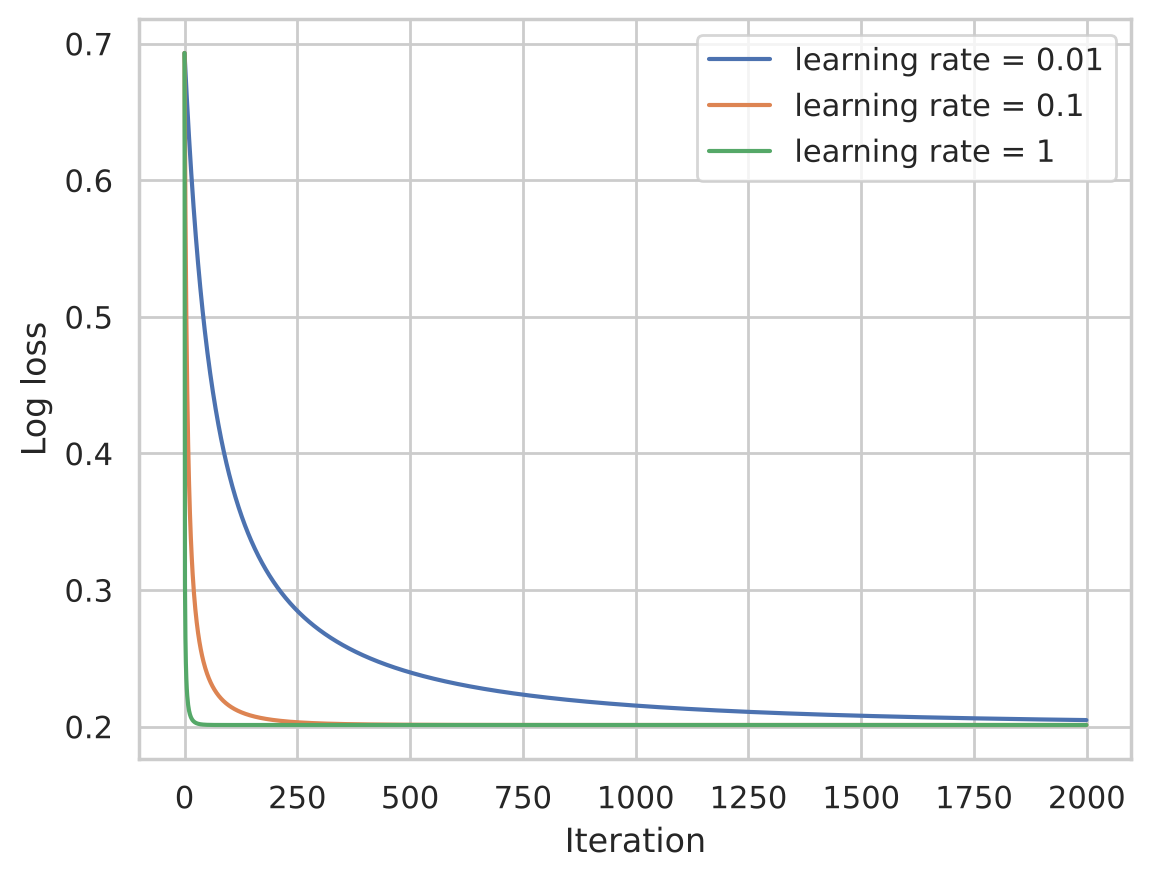

In [2]:
X_toy, y_toy = make_blobs(n_samples=200, centers=[(-1.5, -1), (1.5, 1)], cluster_std=1.2, random_state=0)

def train_logistic(X, y, lr=0.1, n_iter=2000):
    w, b, losses = np.zeros(X.shape[1]), 0.0, []
    for _ in range(n_iter):
        p = 1 / (1 + np.exp(-(X @ w + b)))
        losses.append(-np.mean(y * np.log(p + 1e-12) + (1 - y) * np.log(1 - p + 1e-12)))
        w -= lr * X.T @ (p - y) / len(y)
        b -= lr * np.mean(p - y)
    return losses

for lr in [0.01, 0.1, 1]:
    plt.plot(train_logistic(X_toy, y_toy, lr=lr), label=f"learning rate = {lr}")
plt.xlabel("Iteration")
plt.ylabel("Log loss")
plt.legend()
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

- با نرخ ۰٫۰۱ خطا خیلی آهسته کم می‌شود و حتی بعد از ۲۰۰۰ تکرار هنوز به کمینه نرسیده است.
- با نرخ ۱ همگرایی بسیار سریع است و واگرایی هم رخ نمی‌دهد، چون تابع هزینهٔ لجستیک محدب و نسبتاً «صاف» است و گرادیان آن به خاطر سیگموید محدود می‌ماند.

نرخ یادگیری مناسب به داده و مقیاس ویژگی‌ها بستگی دارد؛ همیشه نمودار خطا را بکشید.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۲

کمترین آستانه‌ای را پیدا کنید که Recall روی دادهٔ سرطان ۱۰۰٪ شود. در این آستانه Precision چقدر است؟

</div>

In [3]:
precisions, recalls, thresholds = precision_recall_curve(y_test, y_proba)
full_recall = recalls[:-1] == 1.0
best = np.argmax(np.where(full_recall, thresholds, -1))
print(f"Highest threshold with 100% recall: {thresholds[best]:.4f}")
print(f"Precision at that threshold:        {precisions[best]:.3f}")
print(f"Patients flagged as malignant:      {(y_proba >= thresholds[best]).sum()} of {len(y_test)}")

Highest threshold with 100% recall: 0.0562
Precision at that threshold:        0.828
Patients flagged as malignant:      64 of 143


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

بالاترین آستانه‌ای که هنوز همهٔ بیماران سرطانی را پیدا می‌کند، بسیار کمتر از ۰٫۵ است، ولی Precision در آن هنوز بالاست؛ یعنی مدل این داده را خیلی خوب رتبه‌بندی می‌کند. در دادهٔ واقعی و بزرگ‌تر، رسیدن به Recall صد درصد معمولاً هزینهٔ بسیار بیشتری در Precision دارد. یادآوری: آستانه‌ای که روی دادهٔ آزمون انتخاب شود، تخمین خوش‌بینانه‌ای می‌دهد (تمرین ۳ روش درست را نشان می‌دهد).

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۳

با `TunedThresholdClassifierCV` و `scoring="f1"` آستانهٔ بهینه را روی دادهٔ آموزش پیدا کنید و نتیجه را روی دادهٔ آزمون گزارش کنید.

</div>

In [4]:
tuned = TunedThresholdClassifierCV(make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
                                   scoring="f1", cv=5).fit(X_train, y_train)
print(f"Threshold chosen by 5-fold CV on the training data: {tuned.best_threshold_:.3f}")
print(f"Test F1 at threshold 0.5:     {f1_score(y_test, log_reg.predict(X_test)):.3f}")
print(f"Test F1 at tuned threshold:   {f1_score(y_test, tuned.predict(X_test)):.3f}\n")
print(classification_report(y_test, tuned.predict(X_test), target_names=["benign", "malignant"], digits=3))

Threshold chosen by 5-fold CV on the training data: 0.545
Test F1 at threshold 0.5:     0.951
Test F1 at tuned threshold:   0.950

              precision    recall  f1-score   support

      benign      0.947     1.000     0.973        90
   malignant      1.000     0.906     0.950        53

    accuracy                          0.965       143
   macro avg      0.974     0.953     0.962       143
weighted avg      0.967     0.965     0.965       143



<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

`TunedThresholdClassifierCV` آستانه را فقط با دادهٔ آموزش و اعتبارسنجی متقابل انتخاب می‌کند؛ پس نتیجهٔ دادهٔ آزمون یک تخمین **بی‌طرفانه** است. در این داده، آستانهٔ پیش‌فرض ۰٫۵ هم تقریباً بهینه است و تفاوت F1 کوچک است. تنظیم آستانه وقتی بیشترین اثر را دارد که کلاس‌ها نامتوازن باشند یا هزینهٔ دو نوع خطا خیلی متفاوت باشد (جلسه‌های ۱۰ و ۱۴).

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۴

ماتریس درهم‌ریختگی دادهٔ Wine را رسم کنید. کدام کلاس‌ها با هم اشتباه گرفته می‌شوند؟

</div>

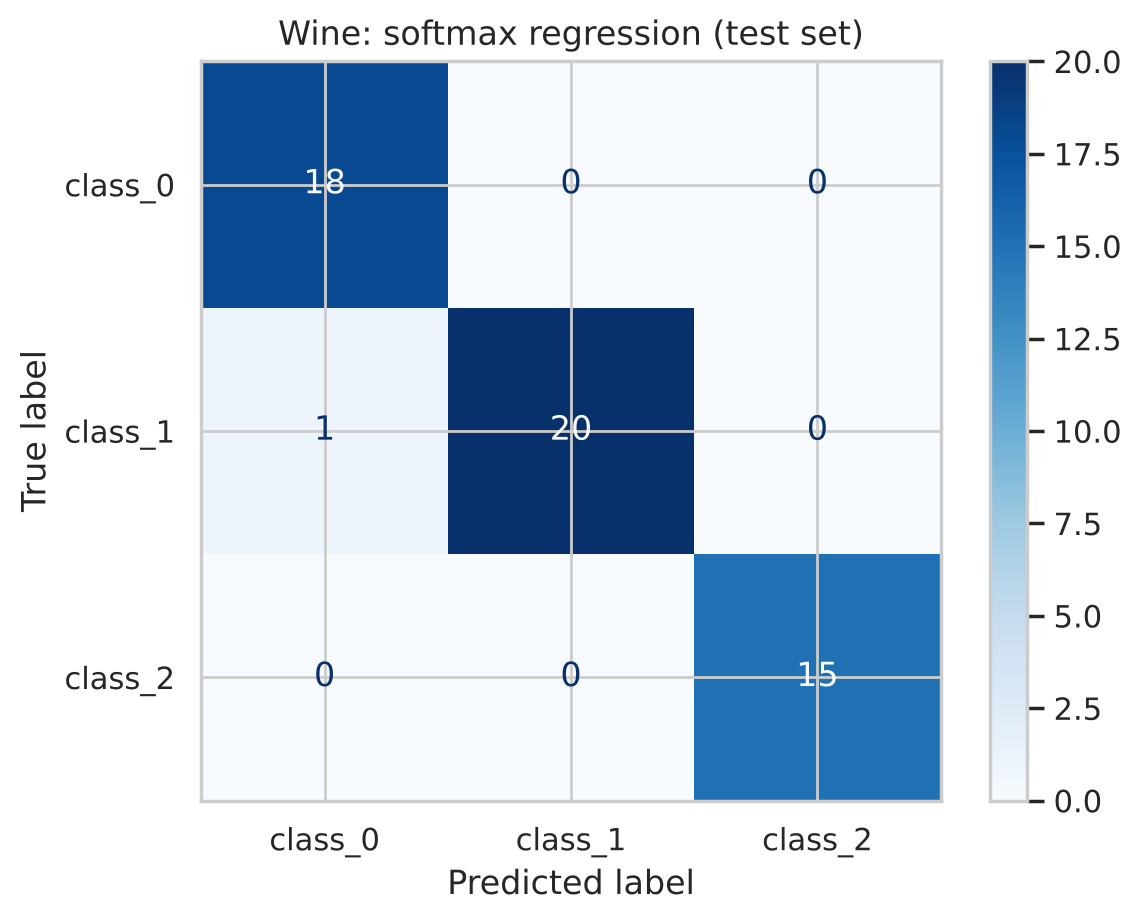

In [5]:
wine = load_wine()
Xw_train, Xw_test, yw_train, yw_test = train_test_split(wine.data, wine.target, test_size=0.3,
                                                        stratify=wine.target, random_state=42)
softmax_reg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xw_train, yw_train)
ConfusionMatrixDisplay.from_estimator(softmax_reg, Xw_test, yw_test, display_labels=wine.target_names,
                                      cmap="Blues")
plt.title("Wine: softmax regression (test set)")
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

مدل تقریباً بدون خطاست. اگر خطایی رخ دهد، معمولاً بین `class_1` با یکی از دو کلاس دیگر است؛ در نمودار PCA جلسهٔ ۱۲ هم می‌بینیم که `class_1` بین دو کلاس دیگر قرار دارد و با هر دو کمی هم‌پوشانی دارد، در حالی که `class_0` و `class_2` از هم دورند.

</div>